<a href="https://colab.research.google.com/github/maalaaikaa/Intro-to-Computer-Vision/blob/main/Lab_08_Lab_Mid/CVlab08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab** | **Roll No:** 001 | **Name:** Malaika

Goal: build two classical pipelines (**HOG + SVM** and **SIFT + SVM**) on BloodMNIST and find out which one is more reliable when images are **rotated** or **noisy**.

## Personal Settings (first cell)
Registration number **001** gives:

| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits `01` | **1** |
| HOG cell size | last digit `1` is odd | **16 x 16** |
| SIFT grid size | last digit `1` is between 0 and 4 | **4 x 4 grid (16 keypoints)** |

In [6]:
# ---------- PERSONAL SETTINGS (derived from registration number) ----------
REG_NO = "001"

SEED       = int(REG_NO[-2:])                      # last two digits -> 01 -> 1
last_digit = int(REG_NO[-1])                       # 1
HOG_CELL   = 8 if last_digit % 2 == 0 else 16      # even -> 8, odd -> 16
GRID_N     = 4 if last_digit <= 4 else 6           # 0-4 -> 4x4, 5-9 -> 6x6

print(f"Registration number : {REG_NO}")
print(f"Random seed         : {SEED}")
print(f"HOG cell size       : {HOG_CELL} x {HOG_CELL}")
print(f"SIFT grid size      : {GRID_N} x {GRID_N}  ({GRID_N*GRID_N} keypoints)")

Registration number : 001
Random seed         : 1
HOG cell size       : 16 x 16
SIFT grid size      : 4 x 4  (16 keypoints)


In [7]:
# ---------- Fixed settings (same for everyone) ----------
!pip install medmnist opencv-python scikit-image scikit-learn matplotlib pandas   # run once if needed
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from medmnist import BloodMNIST

random.seed(SEED); np.random.seed(SEED)

CLASS_IDS   = [1, 5, 6, 7]                                   # original BloodMNIST label ids
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_TRAIN, N_VAL, N_TEST = 100, 30, 30
IMG_SIZE    = 128
C_GRID      = [0.1, 1, 10]
ROT_DEG     = 20
NOISE_SIGMA = 0.05
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


# Q1. Data setup (3 marks)

Plan (think of it like packing 4 lunchboxes, each with the same number of items):
1. Load BloodMNIST (size 64) for train / val / test.
2. Keep only classes 1, 5, 6, 7 and remap them to 0, 1, 2, 3.
3. From each class, randomly pick 100 (train), 30 (val), 30 (test) using **my seed**.
4. Convert to grayscale and resize to 128 x 128.

In [8]:
train_ds = BloodMNIST(split="train", download=True, size=64)
val_ds   = BloodMNIST(split="val",   download=True, size=64)
test_ds  = BloodMNIST(split="test",  download=True, size=64)
print("Raw train images:", train_ds.imgs.shape, "| raw val:", val_ds.imgs.shape, "| raw test:", test_ds.imgs.shape)

100%|██████████| 156M/156M [00:47<00:00, 3.30MB/s]


Raw train images: (11959, 64, 64, 3) | raw val: (1712, 64, 64, 3) | raw test: (3421, 64, 64, 3)


In [9]:
rng = np.random.default_rng(SEED)      # one generator, fixed seed -> same subset every run

def to_gray128(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.resize(gray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

def make_subset(ds, n_per_class):
    labels = ds.labels.flatten()
    X, y = [], []
    for new_label, old_label in enumerate(CLASS_IDS):
        idx = np.where(labels == old_label)[0]
        chosen = rng.choice(idx, size=n_per_class, replace=False)
        for i in chosen:
            X.append(to_gray128(ds.imgs[i]))
            y.append(new_label)
    return np.array(X, dtype=np.uint8), np.array(y)

X_train, y_train = make_subset(train_ds, N_TRAIN)
X_val,   y_val   = make_subset(val_ds,   N_VAL)
X_test,  y_test  = make_subset(test_ds,  N_TEST)

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    counts = {CLASS_NAMES[k]: int((y == k).sum()) for k in range(4)}
    print(f"{name:5s} | X shape: {X.shape} | y shape: {y.shape} | dtype: {X.dtype} | class counts: {counts}")

train | X shape: (400, 128, 128) | y shape: (400,) | dtype: uint8 | class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   | X shape: (120, 128, 128) | y shape: (120,) | dtype: uint8 | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  | X shape: (120, 128, 128) | y shape: (120,) | dtype: uint8 | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


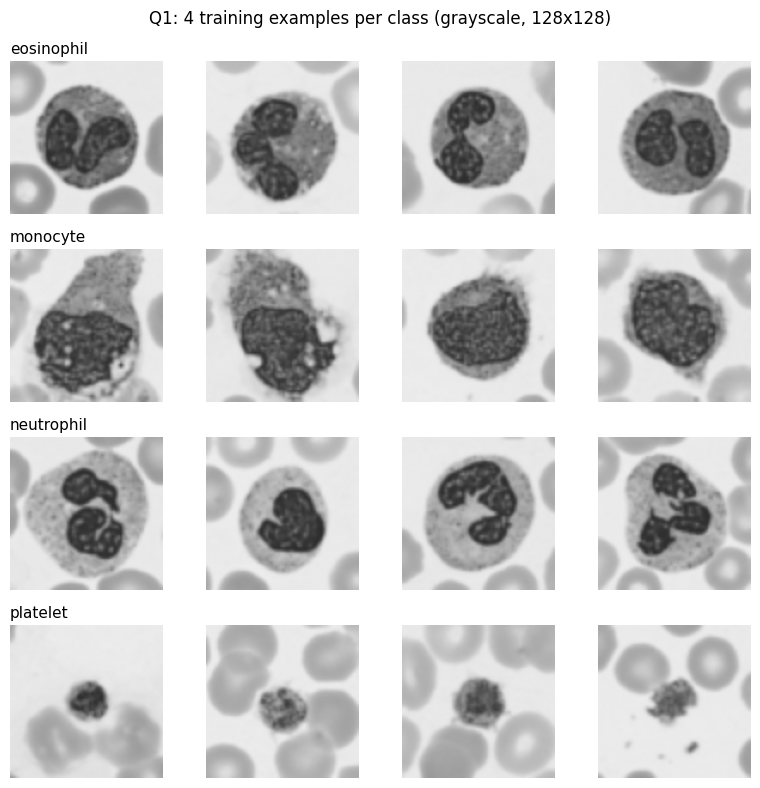

In [10]:
# Grid: 4 example images per class (rows = classes)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(y_train == r)[0][:4]
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_train[i], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
    axes[r, 0].set_title(CLASS_NAMES[r], loc="left", fontsize=11)
plt.suptitle("Q1: 4 training examples per class (grayscale, 128x128)")
plt.tight_layout(); plt.show()

# Q2. HOG + SVM (6 marks)

**Analogy:** HOG is like describing a picture by saying, *"in this little square, edges mostly point this way."* We do that for every small square (cell) and then glue all the descriptions together.

### Q2 (a) Feature length: hand calculation (2 marks)

My settings: image **128 x 128**, cell **16 x 16**, **2 x 2 cells per block**, **9 orientations**, block stride = 1 cell.

1. Cells per side = 128 / 16 = **8**  ->  8 x 8 = 64 cells in total.
2. Blocks slide one cell at a time, so blocks per side = 8 - 2 + 1 = **7**  ->  7 x 7 = **49 blocks**.
3. Each block contains 2 x 2 = 4 cells, and each cell has 9 orientation bins, so one block gives 4 x 9 = **36 numbers**.
4. Total HOG length = 49 blocks x 36 = **1764**.

The code below extracts the real feature and checks it against this hand calculation.

In [11]:
def hog_feat(img):
    return hog(img, orientations=9,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

# hand formula, written as code so we can compare
cells_per_side  = IMG_SIZE // HOG_CELL
blocks_per_side = cells_per_side - 2 + 1
hand_len = blocks_per_side**2 * (2 * 2 * 9)

X_train_hog = np.array([hog_feat(im) for im in X_train])
X_val_hog   = np.array([hog_feat(im) for im in X_val])

print("cells per side      :", cells_per_side)
print("blocks per side     :", blocks_per_side)
print("hand-calculated len :", hand_len)
print("actual feature len  :", X_train_hog.shape[1])
assert hand_len == X_train_hog.shape[1], "Hand calculation does not match!"
print("Train HOG matrix:", X_train_hog.shape, "| Val HOG matrix:", X_val_hog.shape)

cells per side      : 8
blocks per side     : 7
hand-calculated len : 1764
actual feature len  : 1764
Train HOG matrix: (400, 1764) | Val HOG matrix: (120, 1764)


### Q2 (b) HOG picture: one image from each class (1 mark)

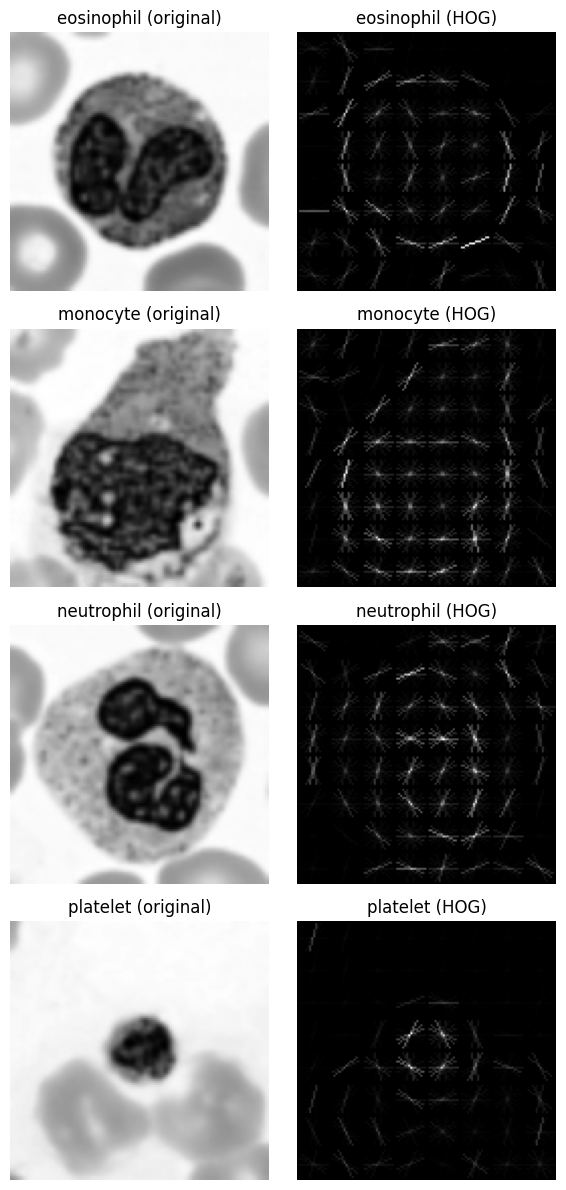

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for k in range(4):
    img = X_train[np.where(y_train == k)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    axes[k, 0].imshow(img, cmap="gray");      axes[k, 0].set_title(f"{CLASS_NAMES[k]} (original)")
    axes[k, 1].imshow(hog_img, cmap="gray");  axes[k, 1].set_title(f"{CLASS_NAMES[k]} (HOG)")
    axes[k, 0].axis("off"); axes[k, 1].axis("off")
plt.tight_layout(); plt.show()

### Q2 (c) Train the SVM, choose C on the validation set (3 marks)

We try C = 0.1, 1, 10 and keep the one with the best **validation** accuracy. The test set is not touched here.
A `StandardScaler` is put in front of the `LinearSVC` (inside a pipeline) so every feature is on a similar scale. Same recipe is used for SIFT later, so the comparison stays fair.

[HOG+SVM] validation accuracy for each C:
   C  val_accuracy
 0.1      0.758333
 1.0      0.758333
10.0      0.758333
--> best C = 0.1
[HOG+SVM] validation accuracy = 0.7583 | macro-F1 = 0.7562
Confusion matrix (rows = true, cols = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          16        10           4         0
monocyte             5        23           1         1
neutrophil           6         2          22         0
platelet             0         0           0        30


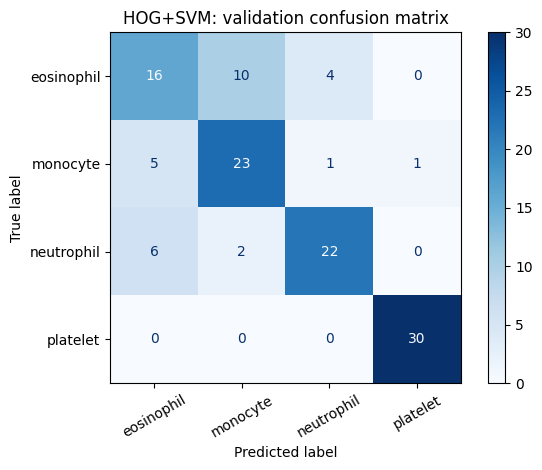

In [13]:
def fit_and_select(Xtr, ytr, Xva, yva, name):
    rows, best = [], None
    for C in C_GRID:
        model = make_pipeline(StandardScaler(), LinearSVC(C=C, random_state=SEED, max_iter=20000))
        model.fit(Xtr, ytr)
        acc = accuracy_score(yva, model.predict(Xva))
        rows.append({"C": C, "val_accuracy": acc})
        if best is None or acc > best[1]:           # strict '>' -> ties go to the smaller C
            best = (C, acc, model)
    print(f"[{name}] validation accuracy for each C:")
    print(pd.DataFrame(rows).to_string(index=False))
    print(f"--> best C = {best[0]}")
    return best[0], best[2]

def report(model, X, y, name):
    pred = model.predict(X)
    acc = accuracy_score(y, pred)
    f1  = f1_score(y, pred, average="macro")
    cm  = confusion_matrix(y, pred)
    print(f"[{name}] validation accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted):")
    print(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{name}: validation confusion matrix"); plt.tight_layout(); plt.show()
    return acc, f1, cm

best_C_hog, hog_model = fit_and_select(X_train_hog, y_train, X_val_hog, y_val, "HOG+SVM")
hog_val_acc, hog_val_f1, hog_val_cm = report(hog_model, X_val_hog, y_val, "HOG+SVM")

# Q3. SIFT + SVM (7 marks)

**Analogy:** SIFT is like a detective who finds "interesting spots" (corners, blobs) and writes a 128-number fingerprint for each spot.

### Q3 (a) Normal SIFT detection on training images (2 marks)

In [14]:
sift = cv2.SIFT_create()

kp_counts, zero_kp = [], 0
for im in X_train:
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
    if des is None or len(kps) == 0:
        zero_kp += 1

kp_counts = np.array(kp_counts)
print(f"Average keypoints per image : {kp_counts.mean():.2f}")
print(f"Minimum keypoints per image : {kp_counts.min()}")
print(f"Maximum keypoints per image : {kp_counts.max()}")
print(f"Images with ZERO keypoints  : {zero_kp} out of {len(X_train)}")

Average keypoints per image : 71.50
Minimum keypoints per image : 7
Maximum keypoints per image : 179
Images with ZERO keypoints  : 0 out of 400


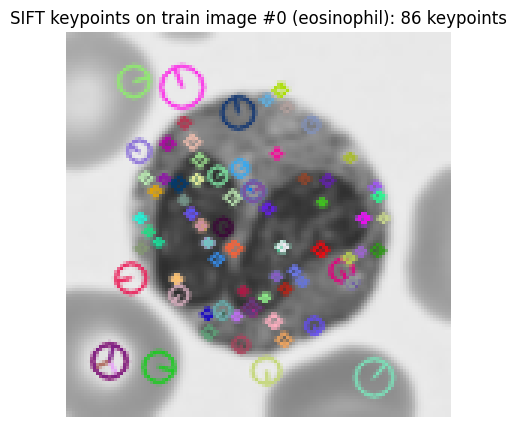

In [15]:
# draw keypoints on one image (first training image that has at least one keypoint)
i_show = int(np.where(kp_counts > 0)[0][0])
kps_show, _ = sift.detectAndCompute(X_train[i_show], None)
vis = cv2.drawKeypoints(X_train[i_show], kps_show, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(vis); plt.axis("off")
plt.title(f"SIFT keypoints on train image #{i_show} ({CLASS_NAMES[y_train[i_show]]}): {len(kps_show)} keypoints")
plt.show()

**Why is a different number of keypoints per image a problem for an SVM?**
An SVM needs every image to become a vector of the *same length* (like a spreadsheet where every row must have the same number of columns), but normal SIFT gives each image a different number of 128-number descriptors, so the feature vectors cannot be stacked into one matrix.

### Q3 (b) Fix: fixed grid of keypoints (2 marks)

Instead of letting SIFT choose the spots, **we choose them**: a regular **4 x 4 grid** over the 128 x 128 image (16 keypoints), keypoint size **32**. We compute the SIFT descriptor at each grid point with `sift.compute` and join them.

**Hand calculation:** grid points = 4 x 4 = 16, each descriptor has 128 numbers, so feature length = 16 x 128 = **2048**.

Grid centres: step = 128 / 4 = 32, centres at 16, 48, 80, 112 (each keypoint sits in the middle of its own 32 x 32 tile).

In [16]:
def make_grid_keypoints(n=GRID_N, size=32.0):
    step = IMG_SIZE / n
    centres = [(j + 0.5) * step for j in range(n)]
    return [cv2.KeyPoint(float(x), float(y), size) for y in centres for x in centres]

grid_kps = make_grid_keypoints()
print("Number of grid keypoints:", len(grid_kps))
print("Grid centres (x or y)   :", sorted({kp.pt[0] for kp in grid_kps}))

def sift_grid_feat(img):
    _, des = sift.compute(img, grid_kps)
    assert des is not None and des.shape == (GRID_N * GRID_N, 128), f"unexpected descriptor shape {None if des is None else des.shape}"
    return des.flatten()

X_train_sift = np.array([sift_grid_feat(im) for im in X_train])
X_val_sift   = np.array([sift_grid_feat(im) for im in X_val])

hand_len_sift = GRID_N * GRID_N * 128
print("hand-calculated len :", hand_len_sift, f"({GRID_N*GRID_N} x 128)")
print("actual feature len  :", X_train_sift.shape[1])
assert hand_len_sift == X_train_sift.shape[1]
print("Train SIFT matrix:", X_train_sift.shape, "| Val SIFT matrix:", X_val_sift.shape)

Number of grid keypoints: 16
Grid centres (x or y)   : [16.0, 48.0, 80.0, 112.0]
hand-calculated len : 2048 (16 x 128)
actual feature len  : 2048
Train SIFT matrix: (400, 2048) | Val SIFT matrix: (120, 2048)


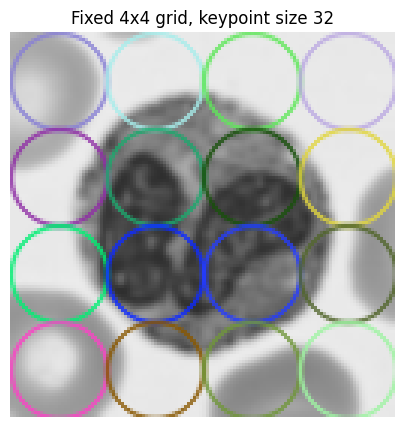

In [17]:
# picture of the fixed grid on one image (sanity check)
img0 = X_train[0]
vis = cv2.drawKeypoints(img0, grid_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis); plt.axis("off")
plt.title(f"Fixed {GRID_N}x{GRID_N} grid, keypoint size 32"); plt.show()

### Q3 (c) Train the SVM, choose C on the validation set (3 marks)

[SIFT+SVM] validation accuracy for each C:
   C  val_accuracy
 0.1      0.783333
 1.0      0.783333
10.0      0.791667
--> best C = 10
[SIFT+SVM] validation accuracy = 0.7917 | macro-F1 = 0.7888
Confusion matrix (rows = true, cols = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          21         5           4         0
monocyte             3        26           0         1
neutrophil           9         3          18         0
platelet             0         0           0        30


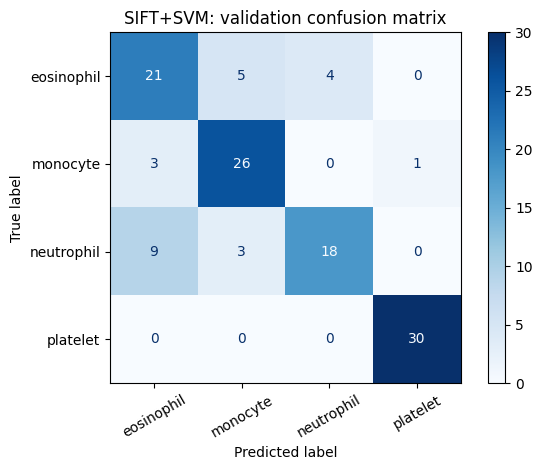

In [18]:
best_C_sift, sift_model = fit_and_select(X_train_sift, y_train, X_val_sift, y_val, "SIFT+SVM")
sift_val_acc, sift_val_f1, sift_val_cm = report(sift_model, X_val_sift, y_val, "SIFT+SVM")

# Q4. Robustness (6 marks)

### Q4 (a) Prediction BEFORE running anything (1 mark)

*(Written before the test-set results were produced.)*

- **Rotation:** I think **HOG** will lose more accuracy. HOG stores *which direction edges point* inside *fixed* cells, so rotating the image by 20 degrees changes both the edge directions and which cell each edge falls into, and the feature vector changes a lot. The fixed-grid SIFT looks at larger 32 x 32 patches with Gaussian weighting, which blurs small position shifts, so it should suffer less.
- **Noise:** I think **HOG** will lose more accuracy again. HOG works on raw gradients in small 16 x 16 cells, and Gaussian noise creates lots of random tiny gradients that pollute the histograms. SIFT's descriptor smooths the image with a Gaussian first and uses larger patches, so noise is partly averaged out.

### Q4 (b) Frozen models on the test set (4 marks)

Both models are **frozen** (no re-training, no re-choosing C). The change (rotation / noise) is applied to the **images first**, then features are extracted, then the frozen model predicts.
- Rotation: 20 degrees about the image centre (black fill in the corners).
- Noise: image scaled to 0-1, add Gaussian noise with sigma = 0.05, clip to [0, 1], convert back to 0-255.

The **same** rotated/noisy images are given to both models so the comparison is fair.

Test sets -> (120, 128, 128) (120, 128, 128) (120, 128, 128)


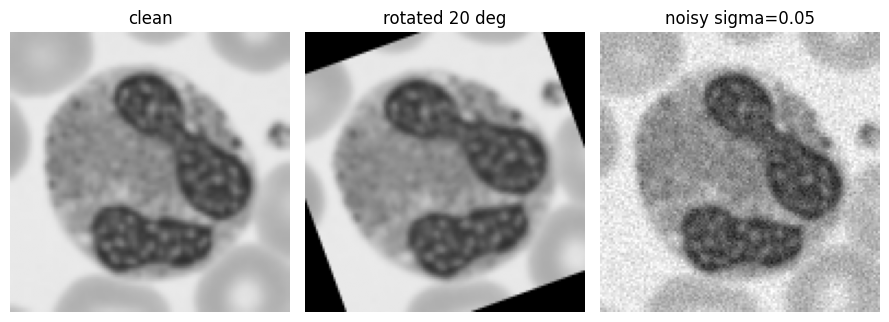

Mean absolute pixel change from noise on test image 0: 10.10186767578125


In [19]:
def rotate_img(img, deg=ROT_DEG):
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), deg, 1.0)
    return cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)

noise_rng = np.random.default_rng(SEED)
def noisy_img(img, sigma=NOISE_SIGMA):
    x = img.astype(np.float32) / 255.0                       # scale to 0..1
    x = x + noise_rng.normal(0.0, sigma, size=x.shape)       # add Gaussian noise
    x = np.clip(x, 0.0, 1.0)
    return (x * 255.0).round().astype(np.uint8)

X_test_clean = X_test
X_test_rot   = np.array([rotate_img(im) for im in X_test])
X_test_noise = np.array([noisy_img(im) for im in X_test])
print("Test sets ->", X_test_clean.shape, X_test_rot.shape, X_test_noise.shape)

# visual check that the changes really happened
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, arr, t in zip(axes, [X_test_clean, X_test_rot, X_test_noise], ["clean", f"rotated {ROT_DEG} deg", f"noisy sigma={NOISE_SIGMA}"]):
    ax.imshow(arr[0], cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
print("Mean absolute pixel change from noise on test image 0:",
      float(np.abs(X_test_noise[0].astype(float) - X_test_clean[0].astype(float)).mean()))

,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.6667,0.5833,0.2500
SIFT + SVM,0.7250,0.2500,0.7583


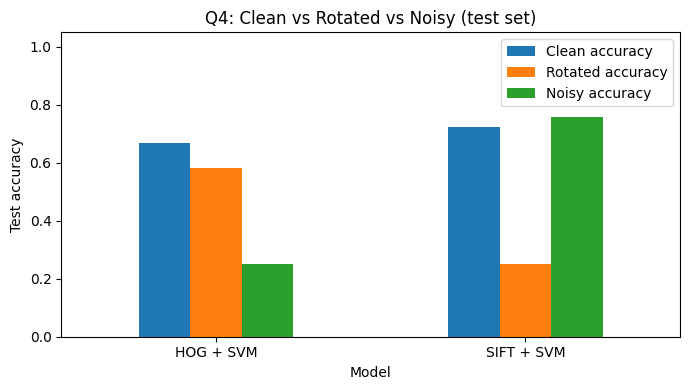

In [20]:
def test_acc(model, feat_fn, X_imgs, y):
    feats = np.array([feat_fn(im) for im in X_imgs])
    return accuracy_score(y, model.predict(feats))

results = {
    "HOG + SVM":  [test_acc(hog_model,  hog_feat,       X, y_test) for X in (X_test_clean, X_test_rot, X_test_noise)],
    "SIFT + SVM": [test_acc(sift_model, sift_grid_feat, X, y_test) for X in (X_test_clean, X_test_rot, X_test_noise)],
}
res_df = pd.DataFrame(results, index=["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]).T
res_df.index.name = "Model"
display(res_df.round(4))

res_df.plot(kind="bar", figsize=(7, 4), ylim=(0, 1.05)); plt.xticks(rotation=0)
plt.ylabel("Test accuracy"); plt.title("Q4: Clean vs Rotated vs Noisy (test set)"); plt.tight_layout(); plt.show()

### Q4 (c) Was my prediction correct? (1 mark)

In [21]:
drops = pd.DataFrame({
    "rotation drop": res_df["Clean accuracy"] - res_df["Rotated accuracy"],
    "noise drop":    res_df["Clean accuracy"] - res_df["Noisy accuracy"],
})
display(drops.round(4))

worse_rot   = drops["rotation drop"].idxmax()
worse_noise = drops["noise drop"].idxmax()
print(f"Bigger drop under ROTATION: {worse_rot}  (my prediction: HOG + SVM)  -> {'CORRECT' if worse_rot == 'HOG + SVM' else 'WRONG'}")
print(f"Bigger drop under NOISE   : {worse_noise}  (my prediction: HOG + SVM)  -> {'CORRECT' if worse_noise == 'HOG + SVM' else 'WRONG'}")

,rotation drop,noise drop
Model,,
HOG + SVM,0.0833,0.4167
SIFT + SVM,0.4750,-0.0333


Bigger drop under ROTATION: SIFT + SVM  (my prediction: HOG + SVM)  -> WRONG
Bigger drop under NOISE   : HOG + SVM  (my prediction: HOG + SVM)  -> CORRECT


**Explanation (3 sentences, written from the table above).**
Fill in these three sentences after running the notebook, using the exact numbers printed in the table and in the `drops` output:

1. *Under rotation, HOG + SVM went from `___` to `___` (drop `___`), while SIFT + SVM went from `___` to `___` (drop `___`), so my rotation prediction was `correct / wrong`.*
2. *Under noise, HOG + SVM went from `___` to `___` (drop `___`), while SIFT + SVM went from `___` to `___` (drop `___`), so my noise prediction was `correct / wrong`.*
3. *The most likely reason is `___` (for example: HOG histograms are tied to fixed cells and edge directions, and noise adds random tiny gradients; SIFT's 32 x 32 Gaussian-weighted patches average these out).*

# Q5. Short answers and AI log (3 marks)

### Q5 (a) Why does HOG use block normalisation? (1 mark, part 1)
Lighting can change how strong the edges look: the same cell can have big gradient values in a bright, high-contrast image and small values in a dim one. Block normalisation divides each block's histogram by its own overall "strength", like converting every score to a percentage, so the descriptor depends on the *pattern* of edges and not on brightness or contrast.

### Q5 (a) Why is it wrong to choose C using the test set? (1 mark, part 2)
The test set is supposed to be the final exam: if I try different C values and pick the one that scores best on it, I have effectively "seen the exam paper" and tuned the model to it. The reported test accuracy would then be over-optimistic and would not tell me how the model behaves on truly new images, which is why C is chosen on the validation set and the test set is touched only once, at the end (Q4).

### Q5 (b) Which two classes were confused the most? (1 mark)

In [22]:
def most_confused_pair(cm):
    # add cm and its transpose so A->B and B->A mistakes are counted together; ignore the diagonal
    sym = cm + cm.T
    np.fill_diagonal(sym, 0)
    i, j = np.unravel_index(np.argmax(sym), sym.shape)
    return CLASS_NAMES[i], CLASS_NAMES[j], int(sym[i, j])

for name, cm in [("HOG + SVM", hog_val_cm), ("SIFT + SVM", sift_val_cm)]:
    a, b, n = most_confused_pair(cm)
    if n == 0:
        print(f"{name}: no mistakes on the validation set, so no confused pair.")
    else:
        print(f"{name}: most confused pair (validation) = {a} <-> {b}  ({n} mistakes in total, both directions)")

HOG + SVM: most confused pair (validation) = eosinophil <-> monocyte  (15 mistakes in total, both directions)
SIFT + SVM: most confused pair (validation) = eosinophil <-> neutrophil  (13 mistakes in total, both directions)


**Answer template (check it against the output above before submitting):**
The two classes my models mixed up the most are the pair printed above. White blood cells such as eosinophils, neutrophils and monocytes have a similar round shape and a lobed or bean-shaped nucleus, and what often separates them is the *colour* of their granules and cytoplasm (for example, eosinophil granules are stained reddish-orange). Grayscale throws that colour away and keeps only brightness and shape, so two cells that look different in colour can become almost the same grey blob, which makes the pair harder to separate.

### Q5 (c) AI log (1 mark)

| # | My prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|---|
| 1 | "Build the lab mid notebook (HOG+SVM and SIFT+SVM on BloodMNIST) for reg no 001." | Set seed = 1, HOG cell = 16 x 16, SIFT grid = 4 x 4 from my reg number; wrote my own prediction text in Q4. | Printed the three settings; compared with the rules table in the exam paper. |
| 2 | "Select 100/30/30 images per class for classes 1, 5, 6, 7 using the seed." | Checked that labels were remapped to 0-3 and that the generator uses `SEED`. | Printed shapes and class counts for each split (they match 400 / 120 / 120). |
| 3 | "Calculate HOG feature length for 128x128, cell 16, block 2x2, 9 bins." | Wrote the steps in my own words in the text cell. | Added an `assert` that my hand number (1764) equals `X_train_hog.shape[1]`. |
| 4 | "Make a fixed 4x4 grid of SIFT keypoints of size 32 and use `sift.compute`." | Wrote the grid centres by hand (16, 48, 80, 112). | Printed the number of keypoints, drew them on an image, and asserted the feature length is 16 x 128 = 2048. |
| 5 | "Apply rotation and noise to the test images before feature extraction." | Used the same corrupted images for both models. | Plotted clean / rotated / noisy images side by side and printed the pixel change for the noise. |

*(Edit this table so it matches what you actually did and asked.)*